**24BAD130 Vishal S DL Lab Exp-04**

**TRANSFER LEARNING USING PRE-TRAINED VISION MODELS FOR IMAGE RECOGNITION**

**PART A — DATASET PREPARATION**

In [ ]:
!pip install -q transformers datasets accelerate kaggle
!pip install -q kagglehub transformers

In [ ]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices("GPU"))

TensorFlow Version: 2.20.0
GPU Available: []


In [ ]:
import kagglehub

path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Dataset downloaded to:")
print(path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Dataset downloaded to:
/kaggle/input/intel-image-classification


In [ ]:
train_dir = os.path.join(path, "seg_train", "seg_train")
test_dir = os.path.join(path, "seg_test", "seg_test")

print("Training directory:", train_dir)
print("Testing directory:", test_dir)

print("\nClasses:")
print(sorted(os.listdir(train_dir)))


Training directory: /kaggle/input/intel-image-classification/seg_train/seg_train
Testing directory: /kaggle/input/intel-image-classification/seg_test/seg_test

Classes:
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = 6
EPOCHS = 5

print("Image Size:", IMG_SIZE)
print("Batch Size:", BATCH_SIZE)
print("Number of Classes:", NUM_CLASSES)

Image Size: (224, 224)
Batch Size: 32
Number of Classes: 6


In [ ]:
# Training and validation data
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    zoom_range=0.2
)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    shuffle=True
)

validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    shuffle=False
)


Found 11230 images belonging to 6 classes.
Found 2804 images belonging to 6 classes.


In [ ]:
# Test data
test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)


Found 3000 images belonging to 6 classes.


In [ ]:
class_names = list(train_generator.class_indices.keys())

print("Class Names:")
print(class_names)

print("\nClass Indices:")
print(train_generator.class_indices)

Class Names:
['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Class Indices:
{'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


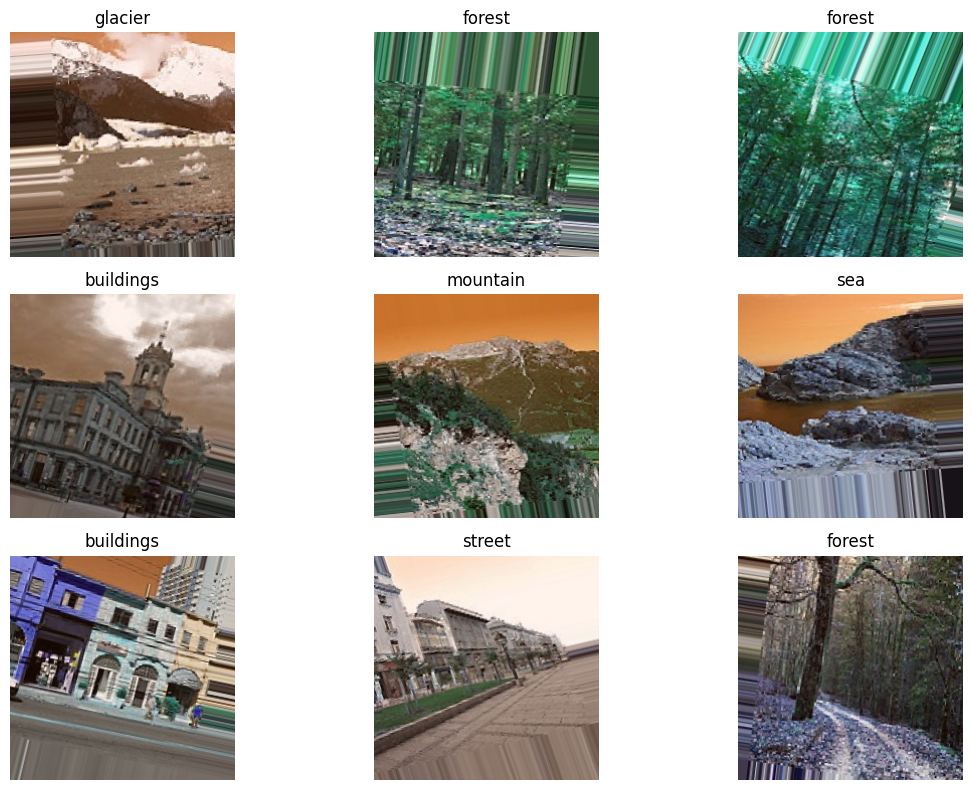

In [ ]:
# Display sample images
images, labels = next(train_generator)

plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)

    img = images[i]
    img = img - img.min()
    img = img / img.max()

    plt.imshow(img)
    plt.title(class_names[np.argmax(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()

**PART B: IMPLEMENTING TRANSFER LEARNING**

In [ ]:
# Load ResNet50 pre-trained on ImageNet
base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("ResNet50 loaded successfully!")
print("Number of base-model layers:", len(base_model.layers))

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
ResNet50 loaded successfully!
Number of base-model layers: 175


In [ ]:
# Freeze feature extraction layers
base_model.trainable = False

print("Base model trainable:", base_model.trainable)
print("Feature extraction layers are frozen.")


Base model trainable: False
Feature extraction layers are frozen.


In [ ]:
# Add a new classification head for the six dataset classes
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,113,798 (91.99 MB)

 Trainable params: 526,086 (2.01 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")


Model compiled successfully!


**PART C: MODEL TRAINING AND PERFORMANCE EVALUATION**

In [ ]:
# Train the transfer learning model
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=EPOCHS
)


Epoch 1/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 2439s 7s/step - accuracy: 0.7573 - loss: 0.6691 - val_accuracy: 0.8887 - val_loss: 0.3072
Epoch 2/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 2485s 7s/step - accuracy: 0.8722 - loss: 0.3568 - val_accuracy: 0.8969 - val_loss: 0.2779
Epoch 3/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 2446s 7s/step - accuracy: 0.8891 - loss: 0.3114 - val_accuracy: 0.9073 - val_loss: 0.2644
Epoch 4/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 2393s 7s/step - accuracy: 0.8973 - loss: 0.2890 - val_accuracy: 0.9141 - val_loss: 0.2465
Epoch 5/5
351/351 ━━━━━━━━━━━━━━━━━━━━ 2393s 7s/step - accuracy: 0.9021 - loss: 0.2708 - val_accuracy: 0.9144 - val_loss: 0.2468


In [16]:
# Evaluate on the test set
test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 523s 6s/step - accuracy: 0.9190 - loss: 0.2238
Test Loss: 0.2237996608018875
Test Accuracy: 0.9190000295639038


In [17]:
# Record final metrics
train_accuracy = history.history["accuracy"][-1]
val_accuracy = history.history["val_accuracy"][-1]
train_loss = history.history["loss"][-1]
val_loss = history.history["val_loss"][-1]

print("Final Training Accuracy   :", round(train_accuracy, 4))
print("Final Validation Accuracy :", round(val_accuracy, 4))
print("Final Training Loss       :", round(train_loss, 4))
print("Final Validation Loss     :", round(val_loss, 4))
print("Test Accuracy             :", round(test_accuracy, 4))

Final Training Accuracy   : 0.9021
Final Validation Accuracy : 0.9144
Final Training Loss       : 0.2708
Final Validation Loss     : 0.2468
Test Accuracy             : 0.919


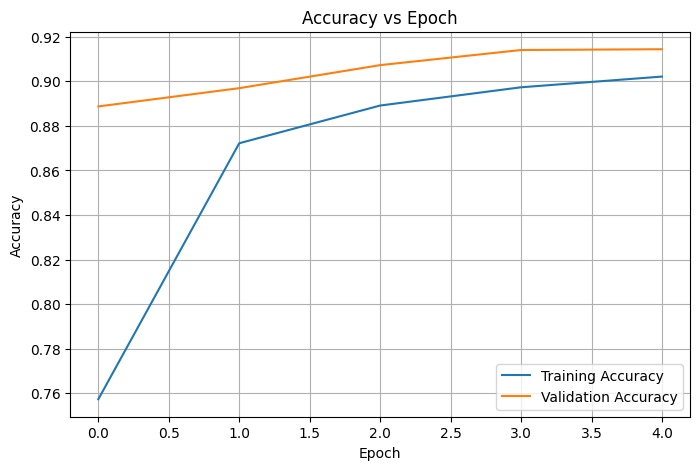

In [18]:
# Accuracy vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


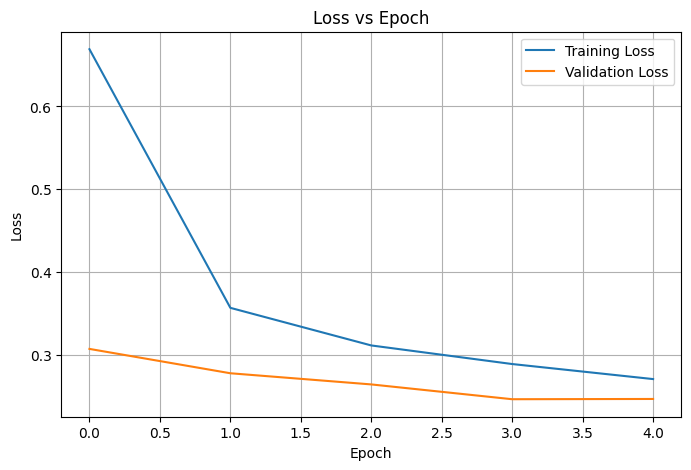

In [19]:
# Loss vs Epoch
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()


**PART D: USING HUGGING FACE PRE-TRAINED MODELS**

In [23]:
from transformers import pipeline
from PIL import Image

hf_model = pipeline(
    "image-classification",
    model="google/vit-base-patch16-224"
)

print("Hugging Face model loaded successfully!")

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Hugging Face model loaded successfully!


In [24]:
# Select a random test image
selected_class = random.choice(class_names)
class_folder = os.path.join(test_dir, selected_class)
image_file = random.choice(os.listdir(class_folder))
image_path = os.path.join(class_folder, image_file)

print("Actual Class:", selected_class)
print("Image:", image_path)

Actual Class: buildings
Image: /kaggle/input/intel-image-classification/seg_test/seg_test/buildings/20597.jpg


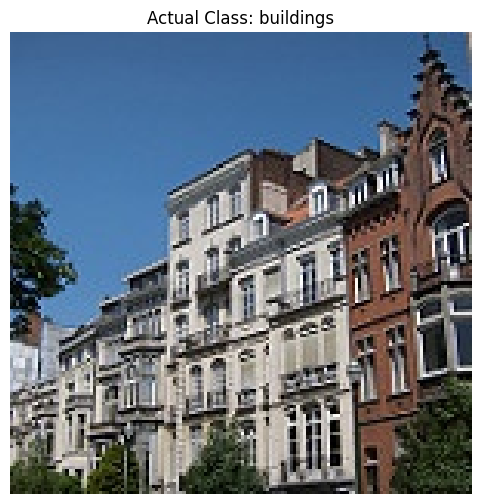

In [25]:
# Display selected image
image = Image.open(image_path).convert("RGB")

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Actual Class: " + selected_class)
plt.axis("off")
plt.show()

In [26]:
# Hugging Face prediction
predictions = hf_model(image)

print("Hugging Face Predictions:\n")

for prediction in predictions:
    print(
        prediction["label"],
        "->",
        round(prediction["score"] * 100, 2),
        "%"
    )


Hugging Face Predictions:

palace -> 50.92 %
monastery -> 7.07 %
streetcar, tram, tramcar, trolley, trolley car -> 2.87 %
library -> 2.43 %
pedestal, plinth, footstall -> 2.21 %


In [27]:
# ResNet50 prediction on the same image
img = image.resize(IMG_SIZE)
img_array = np.array(img, dtype=np.float32)
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

resnet_prediction = model.predict(img_array, verbose=0)

resnet_index = np.argmax(resnet_prediction)
resnet_class = class_names[resnet_index]
resnet_confidence = resnet_prediction[0][resnet_index] * 100

print("Actual Class            :", selected_class)
print("ResNet50 Prediction     :", resnet_class)
print("ResNet50 Confidence     :", round(resnet_confidence, 2), "%")
print("Hugging Face Prediction :", predictions[0]["label"])
print("Hugging Face Confidence :", round(predictions[0]["score"] * 100, 2), "%")

Actual Class            : buildings
ResNet50 Prediction     : buildings
ResNet50 Confidence     : 96.37 %
Hugging Face Prediction : palace
Hugging Face Confidence : 50.92 %


In [31]:
# Simple comparison output

print("              MODEL COMPARISON")
print("-" * 55)
print("Actual Class            :", selected_class)
print("ResNet50 Prediction     :", resnet_class)
print("ResNet50 Confidence     :", round(resnet_confidence, 2), "%")
print("Hugging Face Prediction :", predictions[0]["label"])
print("Hugging Face Confidence :", round(predictions[0]["score"] * 100, 2), "%")



              MODEL COMPARISON
-------------------------------------------------------
Actual Class            : street
ResNet50 Prediction     : buildings
ResNet50 Confidence     : 96.37 %
Hugging Face Prediction : palace
Hugging Face Confidence : 50.92 %


In [32]:
# Test both models on five random images
print("HUGGING FACE VS RESNET50")


for i in range(5):
    selected_class = random.choice(class_names)
    class_folder = os.path.join(test_dir, selected_class)
    image_file = random.choice(os.listdir(class_folder))
    image_path = os.path.join(class_folder, image_file)

    image = Image.open(image_path).convert("RGB")

    # Hugging Face
    hf_prediction = hf_model(image)[0]

    # ResNet50
    img = image.resize(IMG_SIZE)
    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    prediction = model.predict(img_array, verbose=0)
    resnet_index = np.argmax(prediction)

    print("\nImage", i + 1)
    print("Actual Class       :", selected_class)
    print("ResNet50 Prediction:", class_names[resnet_index])
    print("Hugging Face       :", hf_prediction["label"])

HUGGING FACE VS RESNET50

Image 1
Actual Class       : sea
ResNet50 Prediction: sea
Hugging Face       : seashore, coast, seacoast, sea-coast

Image 2
Actual Class       : buildings
ResNet50 Prediction: buildings
Hugging Face       : palace

Image 3
Actual Class       : street
ResNet50 Prediction: street
Hugging Face       : bell cote, bell cot

Image 4
Actual Class       : forest
ResNet50 Prediction: forest
Hugging Face       : park bench

Image 5
Actual Class       : glacier
ResNet50 Prediction: glacier
Hugging Face       : alp
